In [1]:
%pip install pandas numpy matplotlib scikit-learn statsmodels

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split

In [3]:
freq = fetch_openml(data_id=41214, as_frame=True).frame   # one row per policy
sev  = fetch_openml(data_id=41215, as_frame=True).frame   # one row per claim

print(freq.shape, sev.shape)
freq.head()

(678013, 12) (26639, 2)


,IDpol,ClaimNb,Exposure,Area,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Density,Region
0,1.0,1,0.10,D,5,0,55,50,B12,'Regular',1217,R82
1,3.0,1,0.77,D,5,0,55,50,B12,'Regular',1217,R82
2,5.0,1,0.75,B,6,2,52,50,B12,'Diesel',54,R22
3,10.0,1,0.09,B,7,0,46,50,B12,'Diesel',76,R72
4,11.0,1,0.84,B,7,0,46,50,B12,'Diesel',76,R72


In [4]:
freq["IDpol"] = freq["IDpol"].astype(float).astype(int)
sev["IDpol"]  = sev["IDpol"].astype(float).astype(int)

for c in ["ClaimNb", "Exposure", "VehAge", "DrivAge", "BonusMalus"]:
    freq[c] = freq[c].astype(float)

# total claim amount per policy
claims = sev.groupby("IDpol")["ClaimAmount"].sum()
df = freq.merge(claims, on="IDpol", how="left")
df["ClaimAmount"] = df["ClaimAmount"].fillna(0)

# cleaning rules
df["Exposure"] = df["Exposure"].clip(upper=1)               # more than 1 year is a data error
df["ClaimNb"] = df["ClaimNb"].clip(upper=4)                 # a few extreme counts
df.loc[df["ClaimNb"] == 0, "ClaimAmount"] = 0               # no claims means no amount
df["ClaimAmount"] = df["ClaimAmount"].clip(upper=100_000)   # cap very large claims

print(df.shape)
df.describe()

(678013, 13)


,IDpol,ClaimNb,Exposure,VehPower,VehAge,DrivAge,BonusMalus,Density,ClaimAmount
count,6.780130e+05,678013.000000,678013.000000,678013.000000,678013.000000,678013.000000,678013.000000,678013.000000,678013.000000
mean,2.621857e+06,0.053179,0.528545,6.454631,7.044265,45.499122,59.761502,1792.422405,72.648891
std,1.641783e+06,0.237954,0.364081,2.050906,5.666232,14.137444,15.636658,3958.646564,1165.631190
min,1.000000e+00,0.000000,0.002732,4.000000,0.000000,18.000000,50.000000,1.000000,0.000000
25%,1.157951e+06,0.000000,0.180000,5.000000,2.000000,34.000000,50.000000,92.000000,0.000000
50%,2.272152e+06,0.000000,0.490000,6.000000,6.000000,44.000000,50.000000,393.000000,0.000000
75%,4.046274e+06,0.000000,0.990000,7.000000,11.000000,55.000000,64.000000,1658.000000,0.000000
max,6.114330e+06,4.000000,1.000000,15.000000,100.000000,100.000000,230.000000,27000.000000,100000.000000


In [5]:
df["DrivAgeBand"] = pd.cut(df["DrivAge"], [17, 25, 35, 50, 65, 100],
                           labels=["1_18-25", "2_26-35", "3_36-50", "4_51-65", "5_66+"]).astype(str)
df["VehAgeBand"] = pd.cut(df["VehAge"], [-1, 2, 5, 10, 100],
                          labels=["1_0-2", "2_3-5", "3_6-10", "4_11+"]).astype(str)
df["BonusMalus"] = df["BonusMalus"].clip(upper=150)
df["VehGas"] = df["VehGas"].astype(str)
df["Area"] = df["Area"].astype(str)

df[["DrivAge", "DrivAgeBand", "VehAge", "VehAgeBand"]].head()

,DrivAge,DrivAgeBand,VehAge,VehAgeBand
0,55.0,4_51-65,0.0,1_0-2
1,55.0,4_51-65,0.0,1_0-2
2,52.0,4_51-65,2.0,1_0-2
3,46.0,3_36-50,0.0,1_0-2
4,46.0,3_36-50,0.0,1_0-2


In [6]:
df["ClaimNb"] = df["IDpol"].map(sev.groupby("IDpol").size()).fillna(0).clip(upper=4)
# rebuild claim amounts straight from the severity table
df["ClaimAmount"] = (df["IDpol"].map(sev.groupby("IDpol")["ClaimAmount"].sum())
                     .fillna(0).clip(upper=100_000))
print("Policies with claims:", (df["ClaimNb"] > 0).sum(),
      "| with amounts:", (df["ClaimAmount"] > 0).sum())

# split
train, test = train_test_split(df, test_size=0.25, random_state=42)

# Step 6: frequency model
freq_model = smf.glm(
    "ClaimNb ~ C(DrivAgeBand) + C(VehAgeBand) + C(VehGas) + C(Area) + BonusMalus",
    data=train, family=sm.families.Poisson(),
    offset=np.log(train["Exposure"])
).fit()

# severity model
pos = train[(train["ClaimNb"] > 0) & (train["ClaimAmount"] > 0)].copy()
pos["AvgSev"] = pos["ClaimAmount"] / pos["ClaimNb"]
sev_model = smf.glm(
    "AvgSev ~ C(DrivAgeBand) + C(VehGas)", data=pos,
    family=sm.families.Gamma(sm.families.links.Log()),
    var_weights=pos["ClaimNb"]
).fit()

#  pure premium
test = test.copy()
test["pred_freq"] = freq_model.predict(test, offset=np.zeros(len(test)))
test["pred_sev"] = sev_model.predict(test)
test["pred_premium"] = test["pred_freq"] * test["pred_sev"]
test["pred_loss"] = test["pred_premium"] * test["Exposure"]

pred, act = test["pred_loss"].sum(), test["ClaimAmount"].sum()
print("Predicted total loss:", round(pred))
print("Actual total loss:   ", round(act))
print("Gap: ", round((pred / act - 1) * 100, 1), "%")

Policies with claims: 24944 | with amounts: 24944
Predicted total loss: 12042856
Actual total loss:    13153602
Gap:  -8.4 %


In [7]:
tr = train.copy()
tr["pred_loss"] = (freq_model.predict(tr, offset=np.zeros(len(tr)))
                   * sev_model.predict(tr) * tr["Exposure"])
p, a = tr["pred_loss"].sum(), tr["ClaimAmount"].sum()
print("Train predicted:", round(p), "| actual:", round(a), "| gap:", round((p / a - 1) * 100, 1), "%")

Train predicted: 36102781 | actual: 36103290 | gap: -0.0 %


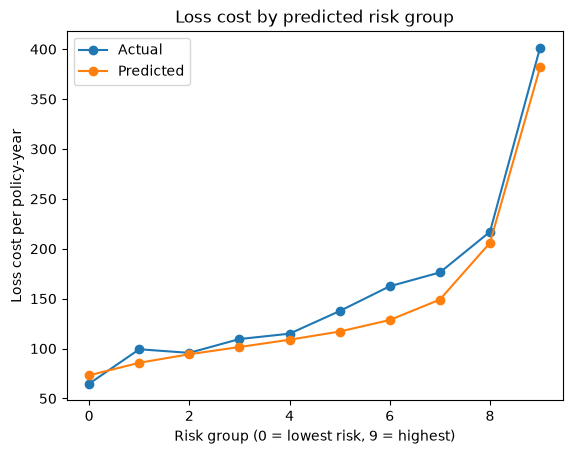

,Actual,Predicted
decile,,
0,65.0,73.0
1,99.0,86.0
2,96.0,94.0
3,110.0,102.0
4,115.0,109.0
5,138.0,117.0
6,162.0,129.0
7,176.0,149.0
8,217.0,206.0


In [8]:
test["decile"] = pd.qcut(test["pred_premium"].rank(method="first"), 10, labels=False)

lift = test.groupby("decile").agg(
    exposure=("Exposure", "sum"),
    actual=("ClaimAmount", "sum"),
    predicted=("pred_loss", "sum")
)
lift["Actual"] = lift["actual"] / lift["exposure"]
lift["Predicted"] = lift["predicted"] / lift["exposure"]

lift[["Actual", "Predicted"]].plot(marker="o", title="Loss cost by predicted risk group")
plt.xlabel("Risk group (0 = lowest risk, 9 = highest)")
plt.ylabel("Loss cost per policy-year")
plt.savefig("lift_chart.png", dpi=150, bbox_inches="tight")
plt.show()

lift[["Actual", "Predicted"]].round(0)

In [9]:
np.exp(freq_model.params).round(2)

Intercept                    0.01
C(DrivAgeBand)[T.2_26-35]    0.85
C(DrivAgeBand)[T.3_36-50]    1.21
C(DrivAgeBand)[T.4_51-65]    1.21
C(DrivAgeBand)[T.5_66+]      1.16
C(VehAgeBand)[T.2_3-5]       1.06
C(VehAgeBand)[T.3_6-10]      1.12
C(VehAgeBand)[T.4_11+]       0.94
C(VehGas)[T.'Regular']       0.83
C(Area)[T.B]                 1.12
C(Area)[T.C]                 1.23
C(Area)[T.D]                 1.40
C(Area)[T.E]                 1.57
C(Area)[T.F]                 1.51
BonusMalus                   1.03
dtype: float64